# Session 6 — From base model to assistant

Sessions 3 to 5 trained models to continue text. A chat assistant is the same kind of model after more training, on conversations and on people's preferences between answers. This session takes Qwen2.5-0.5B, a small open model released in two versions, base and instruct, and works through what that extra training does and how it is done: the chat template, a reward model learned from preference pairs, picking among samples with that reward model, direct preference optimisation (DPO), and rewards that can be checked exactly.

**By the end of the session you should be able to:**

1. compare a base model with its instruction-tuned version and point to the tokens the fine-tuning loss is computed on;
2. train a reward model on preference pairs, measure its accuracy, and show what happens when you optimise against it and check with an independent judge;
3. run DPO and a checkable-reward experiment and say, with numbers, what each one changed.

**To run it yourself** you need the packages from Sessions 0–5 (`torch`, `transformers`, `pandas`, `pyarrow`, `scipy`, `matplotlib`). The notebook downloads Qwen2.5-0.5B and Qwen2.5-0.5B-Instruct (about 1 GB each), Qwen2.5-1.5B-Instruct (2.9 GB) and the UltraFeedback preference data (130 MB). It needs a GPU. On our laptop GPU, reading 24,000 answers for the reward models took about 20 minutes in an earlier run (this saved run loaded the cached vectors), generating the 4,096 samples of section 3 took 863 s and DPO 1,709 s; the whole notebook took 52 minutes with the vectors and the arithmetic samples cached. Finished pieces are cached in `cache/s06_*`, so a re-run skips them. It is not practical on a CPU; the saved outputs are the reference.

In [1]:
import re, time, copy, json, os, warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt
from aij_common import DEVICE, set_seed
import torch, torch.nn.functional as F
from scipy.stats import spearmanr
from huggingface_hub import hf_hub_download
from transformers import AutoTokenizer, AutoModelForCausalLM
from transformers.utils import logging
logging.set_verbosity_error(); set_seed(0); os.makedirs("cache", exist_ok=True)
tok = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-0.5B-Instruct", padding_side="left")      # Qwen2.5-0.5B and 1.5B share this tokenizer and chat template
def load_lm(name): return AutoModelForCausalLM.from_pretrained(name, dtype=torch.bfloat16).to(DEVICE).eval()

The next cell defines the helpers used throughout: the chat template, batched generation, loading the preference data, reading a model's vector for an answer, and fitting a reward model. Presenters skip it on screen; section 2 explains the reward model.

In [2]:
def chat_text(prompt, response=None):
    """The text the instruct model sees: the conversation wrapped in its chat template."""
    msgs = [{"role": "user", "content": prompt}] + ([{"role": "assistant", "content": response}] if response else [])
    return tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=response is None)

@torch.no_grad()
def generate(model, texts, max_new=120, greedy=True, temperature=0.8, batch=64):
    """Generate a continuation for each text (batched, left-padded). Returns the new text only."""
    out = []
    for i in range(0, len(texts), batch):
        enc = tok(texts[i:i + batch], return_tensors="pt", padding=True).to(DEVICE)
        kw = dict(do_sample=False) if greedy else dict(do_sample=True, temperature=temperature, top_p=1.0, top_k=0)
        with torch.autocast("cuda", dtype=torch.bfloat16, enabled=next(model.parameters()).dtype == torch.float32):
            ids = model.generate(**enc, max_new_tokens=max_new, pad_token_id=tok.pad_token_id, **kw)[:, enc.input_ids.shape[1]:]
        out += tok.batch_decode(ids, skip_special_tokens=True)
    return out

def get_pairs(path="cache/s06_pairs.json"):
    """UltraFeedback pairs (prompt, chosen, rejected) whose two conversations both fit in 400 tokens. Filtered once, then cached."""
    if os.path.exists(path): return json.load(open(path))
    sft = pd.read_parquet(hf_hub_download("trl-lib/ultrafeedback_binarized", "data/train-00000-of-00001.parquet", repo_type="dataset"))
    rows = [(r.chosen[0]["content"], r.chosen[-1]["content"], r.rejected[-1]["content"]) for r in sft.itertuples()]
    keep = []
    for i in range(0, len(rows), 1000):
        chunk = rows[i:i + 1000]
        lc = tok([chat_text(p, c) for p, c, _ in chunk]).input_ids; lr = tok([chat_text(p, r) for p, _, r in chunk]).input_ids
        keep += [list(x) for x, a, b in zip(chunk, lc, lr) if len(a) <= 400 and len(b) <= 400]
    json.dump(keep, open(path, "w")); return keep

@torch.no_grad()
def features(model, prompts_, responses, batch=32):
    """One vector per (prompt, answer): the model's last-layer state at the final token."""
    out = []
    for i in range(0, len(responses), batch):
        enc = tok([chat_text(p, r) for p, r in zip(prompts_[i:i + batch], responses[i:i + batch])], return_tensors="pt", padding=True).to(DEVICE)
        with torch.autocast("cuda", dtype=torch.bfloat16): h = model.model(**enc).last_hidden_state[:, -1]      # left padding: the last position is the last real token
        out.append(h.float().cpu())
    return torch.cat(out)

def fit_rm(Xc, Xr, lams=(0, 1e-3, 1e-2, 1e-1, 1, 10), epochs=300):
    """Bradley-Terry linear reward model on frozen features. The L2 strength is chosen on 500 of the training pairs held back for that."""
    both = torch.cat([Xc, Xr]); mu, sd = both.mean(0), both.std(0) + 1e-6; zc, zr = (Xc - mu) / sd, (Xr - mu) / sd
    def train(a, b, lam):
        w = torch.zeros(1, Xc.shape[1], requires_grad=True); opt = torch.optim.Adam([w], lr=1e-3)
        for _ in range(epochs): loss = -F.logsigmoid((a - b) @ w[0]).mean() + lam * (w ** 2).sum(); opt.zero_grad(); loss.backward(); opt.step()
        return w.detach(), loss.item()
    n = len(zc) - 500; acc = {lam: ((zc[n:] - zr[n:]) @ train(zc[:n], zr[:n], lam)[0][0] > 0).float().mean().item() for lam in lams}
    lam = max(acc, key=acc.get); w, loss = train(zc, zr, lam)
    return {"mu": mu, "sd": sd, "w": w, "lam": lam, "train_loss": loss, "lam_scan": acc}
def rm_score(rm, f): return ((f - rm["mu"]) / rm["sd"]) @ rm["w"][0]

## 1. Base and instruct

Both versions have the same architecture, size and tokenizer. The instruct version was trained further by Qwen's developers on conversations and preferences. We give both the same four requests with greedy decoding and 60 new tokens. The base model gets the bare text; the instruct model gets it wrapped in its chat template.

> **Pause:** the base model has read far more text than any assistant has seen conversations. What will it do with "Write a haiku about a flat battery."?

In [3]:
base, inst = load_lm("Qwen/Qwen2.5-0.5B"), load_lm("Qwen/Qwen2.5-0.5B-Instruct")
prompts = ["What is the capital of France?", "Write a haiku about a flat battery.", "Explain in one sentence what a transformer is.", "My phone battery is empty and I have no charger. What should I do?"]
base_out, inst_out = generate(base, prompts, 60), generate(inst, [chat_text(p) for p in prompts], 60)
for p, b, i in zip(prompts, base_out, inst_out): print(f"PROMPT: {p}\n  base    : {b!r}\n  instruct: {i!r}\n")
del base, inst; torch.cuda.empty_cache()

PROMPT: What is the capital of France?
  base    : ' The capital of France is Paris.'
  instruct: 'The capital of France is Paris.'

PROMPT: Write a haiku about a flat battery.
  base    : " A flat battery, oh so simple,\nA battery that can't be touched,\nA battery that can't be touched,\nA battery that can't be touched."
  instruct: 'A flat battery,\nSunk in the void of time,\nCharge fades away.'

PROMPT: Explain in one sentence what a transformer is.
  base    : ' A transformer is a device that changes the voltage of an alternating current (AC) signal.'
  instruct: 'A transformer is a type of neural network architecture designed to process sequential data, such as text or images, by leveraging the power of self-attention mechanisms to capture long-range dependencies between inputs. This allows for more expressive and accurate modeling of complex relationships within large datasets.'

PROMPT: My phone battery is empty and I have no charger. What should I do?
  base    : ' I have a 120

Both answer the capital question. On the other three the base model continues the text the way text on the web continues. The haiku turns into one line repeated three times, and the battery question becomes a forum post that repeats itself. "Transformer" is read as the electrical device, the more common meaning in general text. The instruct model writes a three-line haiku, answers about the neural network, and starts a numbered list of suggestions that the 60-token limit cuts off.

The difference comes from the format the instruct model was trained on. The next cell prints that format, the chat template, for a one-turn conversation.

In [4]:
print(chat_text("Hi", "Hello!"))
ids = tok(chat_text("What is the capital of France?", "Paris."))["input_ids"]; start = len(tok(chat_text("What is the capital of France?"))["input_ids"])
print(f"\n{len(ids)} tokens in this example; the loss is computed on the last {len(ids) - start} (the answer and the end-of-turn marker): {tok.convert_ids_to_tokens(ids[start:])}")

<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>
<|im_start|>user
Hi<|im_end|>
<|im_start|>assistant
Hello!<|im_end|>


40 tokens in this example; the loss is computed on the last 4 (the answer and the end-of-turn marker): ['Paris', '.', '<|im_end|>', 'Ċ']


Each turn sits between `<|im_start|>` and `<|im_end|>` markers with a role name, and the template adds a default system message when none is given. In supervised fine-tuning on conversations the loss is computed on the assistant's tokens only: for the answer "Paris." that is 4 of the 40 tokens (`Paris`, `.`, the end-of-turn marker and the newline after it). The prompt is context. Learning to produce `<|im_end|>` is what lets the model stop, which the base model never did above.

## 2. A reward model from preferences

Supervised fine-tuning needs a written answer for every prompt. Preferences are cheaper to collect: show two answers to the same prompt and record which is better. We use UltraFeedback (Cui et al., 2023) in its binarised form, where each prompt has a preferred and a rejected answer. The ratings come from GPT-4, so "preferred" here means "rated higher by GPT-4". We keep the pairs whose two conversations both fit in 400 tokens.

A reward model turns an answer into a score, trained so that preferred answers score higher. Ours is small. A language model reads the prompt and answer, we take its last-layer vector at the final token, and a linear layer maps the vector to one number. The loss is the Bradley–Terry loss, $-\log\sigma(r_\text{preferred}-r_\text{rejected})$, which depends only on the difference between the two scores.

We train two of them on different pairs: a **proxy** on the 0.5B instruct model's vectors and a **gold** model on the 1.5B instruct model's vectors. Sections 3 and 4 optimise against the proxy and use gold as an independent judge, standing in for a check with people. Reading 24,000 answers with the two models takes about 20 minutes, so the vectors are cached.

In [5]:
pairs = get_pairs(); proxy_tr, gold_tr, val = pairs[:5000], pairs[5000:10000], pairs[-1000:]
print(f"{len(pairs):,} pairs within 400 tokens; proxy trains on {len(proxy_tr):,}, gold on a different {len(gold_tr):,}, both are tested on the same {len(val):,}")
print(f"in the validation pairs the preferred answer is the longer one in {100 * np.mean([len(tok(c).input_ids) > len(tok(r).input_ids) for _, c, r in val]):.0f}% of cases")
def pair_feats(model, ps, tag):
    path = f"cache/s06_feats_{tag}.pt"
    if os.path.exists(path): return torch.load(path)
    fc, fr = features(model, [p for p, _, _ in ps], [c for _, c, _ in ps]), features(model, [p for p, _, _ in ps], [r for _, _, r in ps])
    torch.save((fc, fr), path); return fc, fr
t = time.time(); m05 = load_lm("Qwen/Qwen2.5-0.5B-Instruct")
F05 = {"tr": pair_feats(m05, proxy_tr, "p05_tr"), "val": pair_feats(m05, val, "p05_val")}; del m05; torch.cuda.empty_cache()
m15 = load_lm("Qwen/Qwen2.5-1.5B-Instruct")
F15 = {"tr": pair_feats(m15, gold_tr, "g15_tr"), "val": pair_feats(m15, val, "g15_val")}; del m15; torch.cuda.empty_cache()
print(f"features ready in {time.time() - t:.0f} s (cached in cache/ for the other parts); vector sizes {F05['tr'][0].shape[1]} (0.5B) and {F15['tr'][0].shape[1]} (1.5B)")

25,555 pairs within 400 tokens; proxy trains on 5,000, gold on a different 5,000, both are tested on the same 1,000


in the validation pairs the preferred answer is the longer one in 51% of cases


features ready in 4 s (cached in cache/ for the other parts); vector sizes 896 (0.5B) and 1536 (1.5B)


In the validation pairs the preferred answer is the longer one about half the time (51%), so length alone says little about which answer is better. The L2 penalty on the linear layer is chosen from six strengths, 0 to 10, by accuracy on 500 training pairs held back for that.

In [6]:
rms = {"proxy": fit_rm(*F05["tr"]), "gold": fit_rm(*F15["tr"])}; torch.save(rms, "cache/s06_rm.pt")
len_c = torch.tensor([len(tok(c).input_ids) for _, c, _ in val]); len_r = torch.tensor([len(tok(r).input_ids) for _, _, r in val]); close = (len_c - len_r).abs() <= 20
rows, vs = [], {}
for name, feats in (("proxy", F05), ("gold", F15)):
    rm = rms[name]; sc, sr = rm_score(rm, feats["val"][0]), rm_score(rm, feats["val"][1]); vs[name] = sc - sr
    rows.append({"reward model": name, "backbone": "Qwen2.5-0.5B-Instruct" if name == "proxy" else "Qwen2.5-1.5B-Instruct", "L2 chosen": rm["lam"],
                 "train accuracy": ((rm_score(rm, feats["tr"][0]) - rm_score(rm, feats["tr"][1])) > 0).float().mean().item(), "val accuracy": (vs[name] > 0).float().mean().item(),
                 "val accuracy, lengths within 20 tokens": (vs[name] > 0)[close].float().mean().item(),
                 "corr(reward, length)": spearmanr(torch.cat([sc, sr]), torch.cat([len_c, len_r])).statistic})
display(pd.DataFrame(rows).round(3))
for name in rms: print(f"{name}: accuracy on the 500 held-back training pairs for each L2 strength:", {lam: round(a, 3) for lam, a in rms[name]["lam_scan"].items()})
print(f"'pick the longer answer' on the same pairs: {(len_c > len_r).float().mean():.3f}; the two reward models order the validation pairs the same way in {((vs['proxy'] > 0) == (vs['gold'] > 0)).float().mean():.0%} of cases")

,reward model,backbone,L2 chosen,train accuracy,val accuracy,"val accuracy, lengths within 20 tokens","corr(reward, length)"
0,proxy,Qwen2.5-0.5B-Instruct,0.1,0.682,0.626,0.608,-0.127
1,gold,Qwen2.5-1.5B-Instruct,0.1,0.718,0.655,0.637,-0.113


proxy: accuracy on the 500 held-back training pairs for each L2 strength: {0: 0.604, 0.001: 0.6, 0.01: 0.606, 0.1: 0.634, 1: 0.62, 10: 0.62}
gold: accuracy on the 500 held-back training pairs for each L2 strength: {0: 0.634, 0.001: 0.634, 0.01: 0.634, 0.1: 0.656, 1: 0.64, 10: 0.62}
'pick the longer answer' on the same pairs: 0.513; the two reward models order the validation pairs the same way in 75% of cases


Both reward models beat chance and "pick the longer answer" (0.513): 0.626 for the proxy and 0.655 for gold on the same 1,000 held-out pairs. Training accuracy is a little higher (0.682 and 0.718). The chosen penalty, 0.1, is the best of the six on the held-back pairs, with lower accuracy on both sides of it. Both keep most of their accuracy on pairs whose lengths differ by at most 20 tokens (0.608 and 0.637), and their scores are almost unrelated to length (correlations −0.13 and −0.11), so they have learned something other than length. The two agree on 75% of the pairs.

These are weak judges: about one pair in three is ranked the wrong way. Production reward models are whole fine-tuned language models trained on far more comparisons. Ours is a linear layer on frozen vectors and 5,000 pairs, and the next two sections should be read with that in mind.

## 3. Best-of-N against a proxy

The simplest way to use a reward model needs no training: sample N answers and keep the one it scores highest. We sample 64 answers for each of 64 held-out prompts (temperature 0.8, at most 200 tokens) and score all 4,096 with both reward models. Then, for N from 1 to 64, we pick by the proxy and read the gold score of the pick, averaging over 200 random subsets of each prompt's samples. Scores are standardised over all samples, so 1.0 means one standard deviation above the average sample.

In [7]:
NP, NS = 64, 64; va_prompts = [p for p, _, _ in val[:NP]]; path = "cache/s06_samples.json"
if os.path.exists(path): samples = json.load(open(path)); print(f"{len(samples)} samples loaded from {path}")
else:
    m05 = load_lm("Qwen/Qwen2.5-0.5B-Instruct"); t = time.time()
    samples = generate(m05, [chat_text(p) for p in va_prompts for _ in range(NS)], max_new=200, greedy=False, temperature=0.8, batch=64)
    json.dump(samples, open(path, "w")); print(f"generated {len(samples)} answers in {time.time() - t:.0f} s"); del m05; torch.cuda.empty_cache()
rep = [p for p in va_prompts for _ in range(NS)]
def scored(tag, name, rm_name):
    path = f"cache/s06_scores_{tag}.pt"
    if os.path.exists(path): return torch.load(path)
    m = load_lm(name); s = rm_score(rms[rm_name], features(m, rep, samples)); torch.save(s, path); del m; torch.cuda.empty_cache(); return s
P = scored("proxy", "Qwen/Qwen2.5-0.5B-Instruct", "proxy").view(NP, NS).numpy(); G = scored("gold", "Qwen/Qwen2.5-1.5B-Instruct", "gold").view(NP, NS).numpy()
L = np.array([len(x) for x in tok(samples).input_ids]).reshape(NP, NS)
print(f"{NP} prompts x {NS} samples; correlation between proxy and gold reward over all samples {spearmanr(P.ravel(), G.ravel()).statistic:.2f}; between reward and length: proxy {spearmanr(P.ravel(), L.ravel()).statistic:.2f}, gold {spearmanr(G.ravel(), L.ravel()).statistic:.2f}")

generated 4096 answers in 863 s


64 prompts x 64 samples; correlation between proxy and gold reward over all samples 0.75; between reward and length: proxy -0.58, gold -0.65


Over these samples the two reward models agree fairly well (rank correlation 0.75), and both give lower scores to longer samples (−0.58 and −0.65), much more strongly than on the preference pairs of section 2. We come back to that below.

> **Pause:** as N grows the proxy score of the pick has to rise. Will the gold score rise with it, level off, or fall?

,proxy reward of pick,gold reward of pick,gold reward if gold picked,length of pick,pick beats a random sample under gold,pick was cut off at 200 tokens
N,,,,,,
1,-0.01,-0.01,-0.01,129.06,0.49,0.41
2,0.36,0.23,0.36,124.19,0.58,0.33
4,0.64,0.39,0.62,121.97,0.65,0.29
8,0.86,0.54,0.83,121.67,0.71,0.24
16,1.03,0.66,1.00,122.29,0.76,0.20
32,1.18,0.77,1.15,123.19,0.79,0.17
64,1.31,0.82,1.25,123.36,0.81,0.16


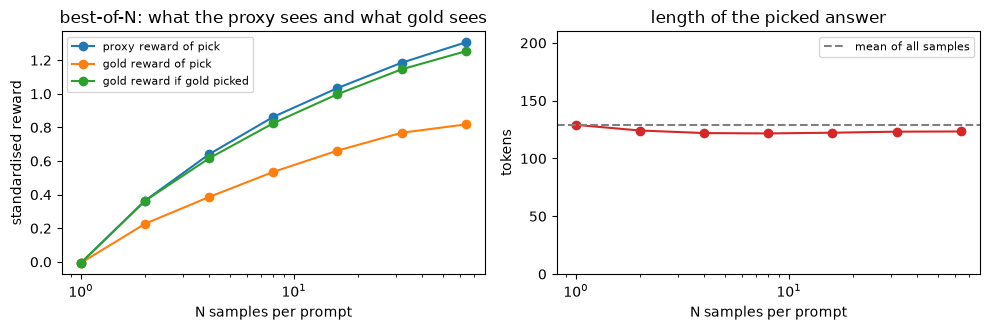

In [8]:
rng = np.random.default_rng(0); z = lambda a: (a - a.mean()) / a.std(); Pz, Gz = z(P), z(G); Ns = [1, 2, 4, 8, 16, 32, 64]; TRIALS = 200; res = []
for N in Ns:
    acc = []
    for _ in range(TRIALS):
        idx = np.stack([rng.choice(NS, N, replace=False) for _ in range(NP)]); pick = np.take_along_axis(Pz, idx, 1).argmax(1); chosen = np.take_along_axis(idx, pick[:, None], 1)[:, 0]
        goldbest = np.take_along_axis(Gz, idx, 1).max(1); rnd = (chosen + rng.integers(1, NS, NP)) % NS; r = np.arange(NP)      # a random other sample of the same prompt
        acc.append((Pz[r, chosen].mean(), Gz[r, chosen].mean(), goldbest.mean(), L[r, chosen].mean(), (Gz[r, chosen] > Gz[r, rnd]).mean(), (L[r, chosen] >= 200).mean()))
    res.append((N, *np.mean(acc, 0)))
res = pd.DataFrame(res, columns=["N", "proxy reward of pick", "gold reward of pick", "gold reward if gold picked", "length of pick", "pick beats a random sample under gold", "pick was cut off at 200 tokens"]).set_index("N"); display(res.round(2))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for col in ("proxy reward of pick", "gold reward of pick", "gold reward if gold picked"): axes[0].plot(res.index, res[col], marker="o", label=col)
axes[0].set(xscale="log", xlabel="N samples per prompt", ylabel="standardised reward", title="best-of-N: what the proxy sees and what gold sees"); axes[0].legend(fontsize=8)
axes[1].plot(res.index, res["length of pick"], marker="o", color="C3"); axes[1].axhline(L.mean(), color="grey", ls="--", label="mean of all samples"); axes[1].legend(fontsize=8)
axes[1].set(xscale="log", ylim=(0, 210), xlabel="N samples per prompt", ylabel="tokens", title="length of the picked answer"); plt.tight_layout(); plt.show()

Gold rises all the way, from 0 at N = 1 to 0.54 at N = 8 and 0.82 at N = 64, and the share of picks that gold prefers to a random other sample of the same prompt goes from 0.49 (chance) to 0.81. Over this range, picking by the proxy also helps by gold's measure.

The gap is the cost of the proxy. Picking by gold itself reaches 1.25 at N = 64; picking by the proxy gets about two thirds of that, while the proxy rates its own picks at 1.31. The proxy's view of its choices pulls further ahead of the judge's as N grows. With much stronger optimisation, Gao et al. (2022) found that the gold score eventually falls (see Going deeper); with 64 samples we see no fall.

The length panel is flat: picks are 122–129 tokens at every N, against 129 for the average sample. The last column of the table shows something else the proxy selects on: 41% of single samples are cut off at the 200-token limit, and by N = 64 only 16% of the picks are.

In [9]:
cut = L >= 200
print(f"{cut.mean():.0%} of the samples stop at the 200-token limit, mid-answer; mean gold reward {G[cut].mean():.2f} for those and {G[~cut].mean():.2f} for answers that finished")
print(f"correlation of gold reward with length among finished answers only: {spearmanr(G[~cut], L[~cut]).statistic:.2f} (all samples: {spearmanr(G.ravel(), L.ravel()).statistic:.2f})")

41% of the samples stop at the 200-token limit, mid-answer; mean gold reward -1.09 for those and 0.26 for answers that finished
correlation of gold reward with length among finished answers only: -0.15 (all samples: -0.65)


Answers cut off mid-sentence score far lower with gold (−1.09, against 0.26 for answers that finished), and among finished answers the link between reward and length is weak (−0.15, against −0.65 over all samples). The strong preference for short samples is mostly a preference for finished ones. Part of best-of-N's gain here is avoiding broken answers, an effect of the 200-token limit we chose for the samples.

## 4. Direct preference optimisation

Best-of-N pays at inference time, with 64 samples for every answer. Fine-tuning moves the preference into the weights. DPO (Rafailov et al., 2023) trains straight from preference pairs, with no reward model and no sampling during training. For each pair it measures how much more likely the policy makes the preferred answer than a frozen copy of the starting model (the reference) does, and the same for the rejected answer, and the loss pushes the first above the second. The difference, times a strength $\beta$ (0.1 here), is the **implicit reward margin**; Going deeper has the formula.

We train the last 4 of the 24 blocks of the instruct model on 6,000 pairs that neither reward model was trained on: 8 pairs per step, learning rate $10^{-5}$, one pass. Policy and reference are both full-precision copies, so at the start the margin is zero.

In [10]:
tr_pairs, va_pairs = pairs[10000:16000], pairs[-1000:]      # disjoint from both reward models' training pairs
LR, BETA, BATCH, ACCUM = 1e-5, 0.1, 2, 4          # 2 pairs per pass, 4 passes per update: 8 pairs per step
def dpo_loss(policy_c, policy_r, ref_c, ref_r, beta=BETA):
    """Direct preference optimisation: raise the chosen answer's probability relative to the rejected one, measured against a frozen reference."""
    margin = beta * ((policy_c - ref_c) - (policy_r - ref_r))
    return -F.logsigmoid(margin).mean(), margin
def sequence_logprob(model, prompts_, responses):
    """Sum of log-probabilities of the answer tokens (and the end-of-turn marker), given the prompt."""
    enc_p = [tok(chat_text(p)).input_ids for p in prompts_]; enc_r = [tok(r + "<|im_end|>").input_ids for r in responses]
    L = max(len(a) + len(b) for a, b in zip(enc_p, enc_r))
    ids = torch.full((len(enc_p), L), tok.pad_token_id); mask = torch.zeros(len(enc_p), L, dtype=torch.bool); attn = torch.zeros(len(enc_p), L, dtype=torch.long)
    for i, (a, b) in enumerate(zip(enc_p, enc_r)):
        ids[i, :len(a) + len(b)] = torch.tensor(a + b); mask[i, len(a):len(a) + len(b)] = True; attn[i, :len(a) + len(b)] = 1
    ids, mask, attn = ids.to(DEVICE), mask.to(DEVICE), attn.to(DEVICE)
    with torch.autocast("cuda", dtype=torch.bfloat16): logits = model(input_ids=ids, attention_mask=attn).logits[:, :-1]
    target_mask = mask[:, 1:]; lp = logits[target_mask].float().log_softmax(-1).gather(1, ids[:, 1:][target_mask][:, None])[:, 0]       # only the answer positions
    return torch.zeros(len(enc_p), device=DEVICE).index_add_(0, torch.arange(len(enc_p), device=DEVICE).repeat_interleave(target_mask.sum(1)), lp)
def pair_logprobs(model, ps, cs, rs):
    both = sequence_logprob(model, ps + ps, cs + rs); return both[:len(ps)], both[len(ps):]

reference = AutoModelForCausalLM.from_pretrained("Qwen/Qwen2.5-0.5B-Instruct", dtype=torch.float32).to(DEVICE).eval()
policy = copy.deepcopy(reference)
for p in list(reference.parameters()) + list(policy.parameters()): p.requires_grad = False
trainable = [p for blk in policy.model.layers[-4:] for p in blk.parameters()] + list(policy.model.norm.parameters())
for p in trainable: p.requires_grad = True
print(f"training the last 4 of {len(policy.model.layers)} blocks: {sum(p.numel() for p in trainable) / 1e6:.0f}M of {sum(p.numel() for p in policy.parameters()) / 1e6:.0f}M parameters; reference is a frozen fp32 copy")
dpo_va = va_pairs[:300]
@torch.no_grad()
def dpo_eval(pairs_, batch=4):
    acc, margins = [], []
    for i in range(0, len(pairs_), batch):
        b = pairs_[i:i + batch]; ps, cs, rs = [x[0] for x in b], [x[1] for x in b], [x[2] for x in b]
        (pc, pr), (rc, rr) = pair_logprobs(policy, ps, cs, rs), pair_logprobs(reference, ps, cs, rs)
        m = BETA * ((pc - rc) - (pr - rr)); acc += ((m > 1e-6).float() + 0.5 * (m.abs() <= 1e-6).float()).tolist(); margins += m.tolist()      # a tie counts as half
    return float(np.mean(acc)), float(np.mean(margins))
before = dpo_eval(dpo_va); print("before training: (preference accuracy, mean margin) on held-out pairs:", before)
assert abs(before[1]) < 1e-4, "policy and reference should start identical"

training the last 4 of 24 blocks: 60M of 494M parameters; reference is a frozen fp32 copy


before training: (preference accuracy, mean margin) on held-out pairs: (0.49833333333333335, -2.7338663765400877e-08)


Before training, the margin on 300 held-out pairs is zero to within $3\times10^{-8}$ and the accuracy is 0.498 (ties count as half), a coin flip. Training takes most of the session's GPU time.

750 steps in 1709 s


after training: (preference accuracy, mean margin) on held-out pairs: (0.6166666666666667, 0.3268578115400548)


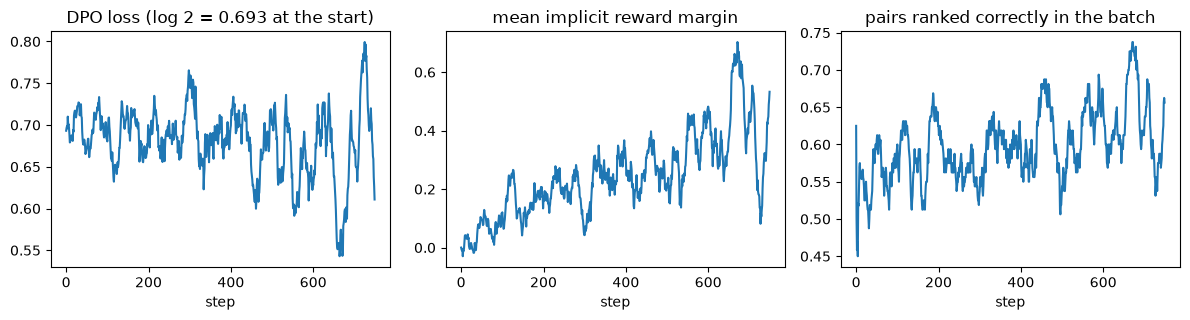

In [11]:
opt = torch.optim.AdamW(trainable, lr=LR, weight_decay=0.0); policy.train(); log = []; t = time.time()
order = np.random.default_rng(0).permutation(len(tr_pairs))
for step, i in enumerate(range(0, len(order) - BATCH * ACCUM + 1, BATCH * ACCUM)):
    losses, margins = [], []
    for k in range(ACCUM):
        b = [tr_pairs[j] for j in order[i + k * BATCH:i + (k + 1) * BATCH]]; ps, cs, rs = [x[0] for x in b], [x[1] for x in b], [x[2] for x in b]
        with torch.no_grad(): rc, rr = pair_logprobs(reference, ps, cs, rs)
        pc, pr = pair_logprobs(policy, ps, cs, rs)
        loss, margin = dpo_loss(pc, pr, rc, rr); (loss / ACCUM).backward(); losses.append(loss.item()); margins.append(margin.detach())
    torch.nn.utils.clip_grad_norm_(trainable, 1.0); opt.step(); opt.zero_grad(); margin = torch.cat(margins)
    log.append({"step": step, "loss": np.mean(losses), "margin": margin.mean().item(), "accuracy": (margin > 0).float().mean().item()})
policy.eval(); log = pd.DataFrame(log); print(f"{len(log)} steps in {time.time() - t:.0f} s")
after = dpo_eval(dpo_va); print("after training: (preference accuracy, mean margin) on held-out pairs:", after)
sm = log.rolling(20, min_periods=1).mean(); fig, axes = plt.subplots(1, 3, figsize=(12, 3.3))
for ax, col, title in zip(axes, ("loss", "margin", "accuracy"), ("DPO loss (log 2 = 0.693 at the start)", "mean implicit reward margin", "pairs ranked correctly in the batch")): ax.plot(log.step, sm[col]); ax.set(xlabel="step", title=title)
plt.tight_layout(); plt.show()

The 750 steps took 1,709 s. Held-out accuracy rose from 0.498 to 0.617, close to the two reward models, and the mean margin to 0.33. In the plots the margin climbs steadily while the loss falls only a little below its starting value of 0.693, and with 8 pairs per step the curves are noisy even after smoothing over 20 steps.

The real test is the answers the model writes. The next cell generates answers to 64 other held-out prompts before and after DPO (greedy, up to 300 tokens) and scores both versions with both reward models.

In [12]:
test_prompts = [p for p, _, _ in va_pairs[300:364]]
def answers(model): return generate(model, [chat_text(p) for p in test_prompts], 300, batch=32)
before_text, after_text = answers(reference), answers(policy)
before_len, after_len = (np.array([len(x) for x in tok(t_).input_ids]) for t_ in (before_text, after_text))
del policy, reference, opt; torch.cuda.empty_cache()
score = {}
for name, lm, rm_name in (("proxy", "Qwen/Qwen2.5-0.5B-Instruct", "proxy"), ("gold", "Qwen/Qwen2.5-1.5B-Instruct", "gold")):
    m = load_lm(lm); score[name] = tuple(rm_score(rms[rm_name], features(m, test_prompts, t_)).numpy() for t_ in (before_text, after_text)); del m; torch.cuda.empty_cache()
display(pd.DataFrame({"mean reward before": {k: v[0].mean() for k, v in score.items()}, "mean reward after DPO": {k: v[1].mean() for k, v in score.items()},
                      "share of prompts where the DPO answer scores higher": {k: (v[1] > v[0]).mean() for k, v in score.items()}}).round(3))
print(f"mean answer length over {len(test_prompts)} held-out prompts (greedy, up to 300 tokens): before {before_len.mean():.0f}, after DPO {after_len.mean():.0f}; answers that hit the 300-token limit: {np.mean(before_len >= 300):.0%} before, {np.mean(after_len >= 300):.0%} after; correlation of reward change and length change (gold): {spearmanr(score['gold'][1] - score['gold'][0], after_len - before_len).statistic:.2f}")
i = int(np.argsort(after_len - before_len)[len(test_prompts) // 2]); print(f"\nA prompt with the median change in length.\nPROMPT: {test_prompts[i][:200]}\n--- before ({before_len[i]} tokens)\n{before_text[i][:500]}\n--- after ({after_len[i]} tokens)\n{after_text[i][:500]}")

,mean reward before,mean reward after DPO,share of prompts where the DPO answer scores higher
proxy,0.044,0.251,0.547
gold,0.109,0.314,0.562


mean answer length over 64 held-out prompts (greedy, up to 300 tokens): before 141, after DPO 180; answers that hit the 300-token limit: 30% before, 25% after; correlation of reward change and length change (gold): -0.06

A prompt with the median change in length.
PROMPT: Teacher:You will be given a trivia clue, and the category it belongs to. You should answer with the best answer that belongs in the category and is described by the clue. For simplicity, answers shoul
--- before (2 tokens)
altered
--- after (10 tokens)
alterations experts for president zachary - zachary


Both judges score the DPO answers higher on average (proxy 0.04 → 0.25, gold 0.11 → 0.31), but prompt by prompt the DPO answer wins on 55% (proxy) and 56% (gold) of the 64 prompts. With 64 prompts the standard error of a share near one half is about 6 points, so this is a small improvement. The clearer change is length: answers grew from 141 to 180 tokens on average, while the share reaching the 300-token limit fell from 30% to 25%. The change in gold reward is unrelated to the change in length (correlation −0.06).

The printed example is the prompt with the median change in length, a trivia clue. Before DPO the model answers with one word, after it with a garbled phrase. One example settles nothing, but it is a reminder that preference training changes the answer to every prompt, including ones it does not improve.

A re-run of these cells gives slightly different numbers in this last table: the training is close to repeatable on this GPU, but 300 tokens of greedy generation magnify tiny numerical differences. Session 11 measures variation like this properly.

## 5. Rewards you can check

For some tasks the reward needs no model: an arithmetic answer is right or wrong, and code passes its tests or fails. Recent reasoning models are trained with rewards like these. Here we measure what such training starts from: how often the instruct model multiplies two two-digit numbers correctly, asked two ways, on 200 problems with 8 samples each at temperature 0.7:

- **just the number**, at most 40 tokens;
- **step by step**, at most 400 tokens, ending with `Answer: <number>`.

Besides pass@1 (the share of single samples that are right), we count a majority vote over the 8 samples and pass@8 (at least one of the 8 is right), which is what you get when a checker can pick out the right one.

In [13]:
m05 = load_lm("Qwen/Qwen2.5-0.5B-Instruct"); K = 8
rng = np.random.default_rng(0); problems = [(int(a), int(b)) for a, b in rng.integers(12, 100, (200, 2))]
def extract(text):
    m = re.findall(r"answer\s*:\s*\**\s*(-?\d[\d,]*)", text.replace("*", ""), flags=re.I) or re.findall(r"-?\d[\d,]*", text.replace("*", ""))
    return int(m[-1].replace(",", "")) if m else None
styles = {"answer with just the number": (lambda a, b: f"What is {a} times {b}? Reply with just the number.", 40),
          "think step by step": (lambda a, b: f"What is {a} times {b}? Work through it step by step, then end with 'Answer: <number>'.", 400)}
outs = {}
for name, (make, max_new) in styles.items():
    path = f"cache/s06_arith_{name.split()[0]}.json"
    if os.path.exists(path): outs[name] = json.load(open(path)); print(f"{name}: {len(outs[name])} samples loaded from {path}"); continue
    t = time.time(); outs[name] = generate(m05, [chat_text(make(a, b)) for a, b in problems for _ in range(K)], max_new=max_new, greedy=False, temperature=0.7, batch=200)
    json.dump(outs[name], open(path, "w")); print(f"{name}: {len(outs[name])} samples in {time.time() - t:.0f} s")

answer with just the number: 1600 samples loaded from cache/s06_arith_answer.json
think step by step: 1600 samples loaded from cache/s06_arith_think.json


> **Pause:** which style will have the higher pass@1, and which the higher pass@8?

,pass@1,majority vote of 8,pass@8 (a checker picks),mean tokens,no 'Answer:' line,hit the token limit
answer with just the number,0.305,0.315,0.48,4.361,1.000,0.00
think step by step,0.259,0.590,0.82,201.476,0.111,0.05


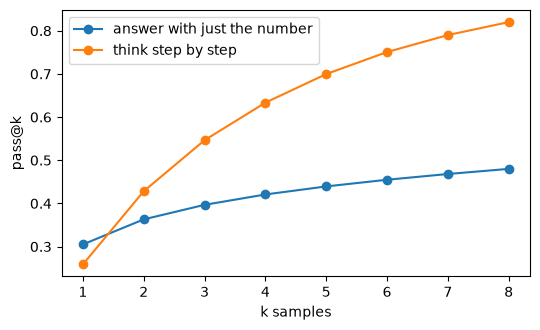

In [14]:
from math import comb
truth = np.array([a * b for a, b in problems]); rows = {}; curves = {}
for name, o in outs.items():
    pred = [extract(x) for x in o]; ok = np.array([p == t_ for p, t_ in zip(pred, np.repeat(truth, K))]).reshape(-1, K); c = ok.sum(1)
    votes = [max(set(v), key=v.count) if (v := [x for x in pred[i * K:(i + 1) * K] if x is not None]) else None for i in range(len(problems))]
    curves[name] = [np.mean(1 - np.array([comb(K - ci, k) / comb(K, k) for ci in c])) for k in range(1, K + 1)]
    ntok = np.array([len(x) for x in tok(o).input_ids])
    rows[name] = {"pass@1": ok.mean(), "majority vote of 8": np.mean([v == t_ for v, t_ in zip(votes, truth)]), "pass@8 (a checker picks)": ok.any(1).mean(),
                  "mean tokens": ntok.mean(), "no 'Answer:' line": np.mean(["answer" not in x.lower() for x in o]), "hit the token limit": np.mean(ntok >= styles[name][1])}
display(pd.DataFrame(rows).T.round(3))
plt.figure(figsize=(5.5, 3.4))
for name, cv in curves.items(): plt.plot(range(1, K + 1), cv, marker="o", label=name)
plt.xlabel("k samples"); plt.ylabel("pass@k"); plt.legend(); plt.tight_layout(); plt.show()

A single step-by-step answer is right less often than a bare number: 0.259 against 0.305, at 201 tokens per answer against 4. Only 5% of the worked answers hit the 400-token limit, so truncation explains little of the gap. 11% never write the `Answer:` line, and the rest of the misses are slips along the way.

With 8 samples the order flips. For bare numbers a majority vote barely helps (0.315 against 0.305), because the 8 samples mostly agree, right or wrong. For worked answers the vote reaches 0.590, and a checker that picks a right sample reaches 0.82 against 0.48. The pass@k curves cross between k = 1 and k = 2.

That gap between pass@1 and pass@8 is what training with a checkable reward uses: reward the samples that reach the right answer, and the model shifts towards whatever produced them, pulling pass@1 up towards pass@8. Running that training is beyond this session's GPU budget; Going deeper describes it.

## What to take away

- An instruct model is a base model trained further on conversations in a fixed template. The loss covers the assistant's tokens, including the end-of-turn marker that lets it stop.
- A reward model is a classifier of pairs. Measure it on held-out pairs and against simple baselines such as length before trusting it; ours ranks about one pair in three the wrong way.
- When you optimise against a learned reward, judge the result with something you did not optimise against. Best-of-64 kept improving under the gold judge but reached about two thirds of what gold itself could pick, and part of the gain came from avoiding cut-off answers.
- DPO learned the preference (held-out ranking 0.498 → 0.617) and made answers longer; judged independently, the quality change was small.
- When an answer can be checked, sampling several and voting or checking is a strong baseline: a majority vote over 8 worked answers nearly doubled accuracy on multiplication.

---

# Going deeper

Reading for after the session.

## The usual pipeline

Ouyang et al. (2022), *Training language models to follow instructions with human feedback* (InstructGPT), set out the recipe most assistants started from: supervised fine-tuning on written demonstrations, a reward model trained on human comparisons, then reinforcement learning (PPO) against that reward model with a penalty on the KL divergence from the fine-tuned model. The penalty keeps the policy close to text the reward model has seen, which limits how far it can exploit the reward model's mistakes.

## From the reward model to DPO

With a KL penalty of strength $\beta$, the best policy for a reward $r$ has a closed form: $\pi^*(y\mid x)\propto\pi_\text{ref}(y\mid x)\,e^{r(x,y)/\beta}$. Turned around, every policy implies a reward, $r(x,y)=\beta\log\frac{\pi(y\mid x)}{\pi_\text{ref}(y\mid x)}$ plus a term that depends only on the prompt. Putting that implied reward into the Bradley–Terry loss of section 2 gives the DPO loss of Rafailov et al. (2023), *Direct Preference Optimization: Your Language Model is Secretly a Reward Model*:

$$-\log\sigma\Big(\beta\big[\log\tfrac{\pi(y_w\mid x)}{\pi_\text{ref}(y_w\mid x)}-\log\tfrac{\pi(y_l\mid x)}{\pi_\text{ref}(y_l\mid x)}\big]\Big)$$

where $y_w$ is the preferred and $y_l$ the rejected answer. The prompt-only term cancels. No separate reward model and no sampling during training are needed; the "implicit reward margin" plotted in section 4 is the bracket times $\beta$.

## Overoptimisation

Gao, Schulman and Hilton (2022), *Scaling Laws for Reward Model Overoptimization*, used the same design as sections 3 and 4 at much larger scale: a large "gold" reward model stands in for people, and smaller proxy reward models trained on its labels are optimised by best-of-$n$ and by reinforcement learning. As optimisation pressure grows, the proxy score keeps rising while the gold score rises, peaks and falls, and the peak comes later for larger proxy models. They measured pressure as the KL divergence from the starting policy, which for best-of-$n$ is $\log n-\frac{n-1}{n}$; at $n=64$ that is 3.2 nats.

## Checkable rewards

Cobbe et al. (2021), *Training Verifiers to Solve Math Word Problems*, sampled many solutions and trained a verifier to pick one. Wang et al. (2022), *Self-Consistency Improves Chain of Thought Reasoning in Language Models*, showed that a majority vote over sampled reasoning paths beats a single greedy answer, the effect in section 5. Training on such rewards with reinforcement learning is how recent reasoning models are built; DeepSeek-AI (2025) describe one, DeepSeek-R1, trained with rule-based rewards for correctness and format using GRPO, a PPO variant introduced by Shao et al. (2024) in *DeepSeekMath*.

## The pass@k estimator

With $n$ samples of which $c$ are right, the chance that at least one of $k$ samples drawn without replacement is right is $1-\binom{n-c}{k}/\binom{n}{k}$. Chen et al. (2021), *Evaluating Large Language Models Trained on Code*, introduced this estimator; section 5 averages it over the 200 problems with $n=8$.